Step 1: Import Libraries
# Import Required Libraries

# Imported pandas and numpy libraries for data cleaning and analysis.

In [2]:
import pandas as pd 
import numpy as np

Step 2: Load Dataset
# Load Dataset

Loaded the company dataset into a pandas DataFrame for further analysis.

In [3]:
import pandas as pd 
import numpy as np 
df = pd.read_csv(r"D:\Debugshala\Python\pandas\messy-company-data-10000.csv")
print(df)



      Index      Row ID      Raw Company Name  \
0         1  4j7zmaQ6yh            salesforce   
1         2  cQB2AsJVqW            The Twilio   
2         3  cVY6kNfRVE          HubSpot (US)   
3         4  rD1WoFe9if           OpenAI (HQ)   
4         5  p7lfn7rqbC         Shopify, GmbH   
...     ...         ...                   ...   
9995   9996  kV4bjYPW2p           Notion (US)   
9996   9997  iroCUBfwvI          Shopify, PLC   
9997   9998  dlvWy4kLHD             ATLASSIAN   
9998   9999  gPqcL1b3pv  Cloudflare (old CRM)   
9999  10000  MdF9RbPN6A     Shopify (old CRM)   

                              Website  \
0                  www.salesforce.com   
1                      www.twilio.com   
2             https://www.hubspot.com   
3                  https://openai.com   
4            https://www.shopify.com/   
...                               ...   
9995                    www.notion.so   
9996         https://www.shopify.com/   
9997        https://www.atlassian.com   
9

Step 3: Check Missing Values
# Missing Value Analysis

Identified null values in all columns to determine the cleaning strategy

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 17 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Index                10000 non-null  int64
 1   Row ID               10000 non-null  str  
 2   Raw Company Name     10000 non-null  str  
 3   Website              10000 non-null  str  
 4   Company Description  10000 non-null  str  
 5   Country              8313 non-null   str  
 6   Source System        10000 non-null  str  
 7   Account Owner        8012 non-null   str  
 8   Created Date         9029 non-null   str  
 9   Last Activity Date   8965 non-null   str  
 10  Renewal Date         9015 non-null   str  
 11  Lifecycle Stage      8008 non-null   str  
 12  Employee Count       9151 non-null   str  
 13  Annual Revenue       8272 non-null   str  
 14  Lead Score           9286 non-null   str  
 15  Open Opportunities   8562 non-null   str  
 16  CRM Notes            10000 non-nul

In [5]:
df.shape

(10000, 17)

In [6]:
df.describe()

,Index
count,10000.00000
mean,5000.50000
std,2886.89568
min,1.00000
25%,2500.75000
50%,5000.50000
75%,7500.25000
max,10000.00000


In [7]:
df.head

<bound method NDFrame.head of       Index      Row ID      Raw Company Name  \
0         1  4j7zmaQ6yh            salesforce   
1         2  cQB2AsJVqW            The Twilio   
2         3  cVY6kNfRVE          HubSpot (US)   
3         4  rD1WoFe9if           OpenAI (HQ)   
4         5  p7lfn7rqbC         Shopify, GmbH   
...     ...         ...                   ...   
9995   9996  kV4bjYPW2p           Notion (US)   
9996   9997  iroCUBfwvI          Shopify, PLC   
9997   9998  dlvWy4kLHD             ATLASSIAN   
9998   9999  gPqcL1b3pv  Cloudflare (old CRM)   
9999  10000  MdF9RbPN6A     Shopify (old CRM)   

                              Website  \
0                  www.salesforce.com   
1                      www.twilio.com   
2             https://www.hubspot.com   
3                  https://openai.com   
4            https://www.shopify.com/   
...                               ...   
9995                    www.notion.so   
9996         https://www.shopify.com/   
9997        

In [8]:
df.isnull().sum()

Index                     0
Row ID                    0
Raw Company Name          0
Website                   0
Company Description       0
Country                1687
Source System             0
Account Owner          1988
Created Date            971
Last Activity Date     1035
Renewal Date            985
Lifecycle Stage        1992
Employee Count          849
Annual Revenue         1728
Lead Score              714
Open Opportunities     1438
CRM Notes                 0
dtype: int64

In [9]:
missing = df.isnull().sum().sort_values(ascending=False)
print(missing)

Lifecycle Stage        1992
Account Owner          1988
Annual Revenue         1728
Country                1687
Open Opportunities     1438
Last Activity Date     1035
Renewal Date            985
Created Date            971
Employee Count          849
Lead Score              714
Index                     0
Source System             0
Company Description       0
Row ID                    0
Raw Company Name          0
Website                   0
CRM Notes                 0
dtype: int64


In [10]:
print("Duplicates:", df.duplicated().sum())

df = df.drop_duplicates()

Duplicates: 0


In [11]:
text_cols = df.select_dtypes(include="object").columns

for col in text_cols:
    df[col] = df[col].astype(str).str.strip()

C:\Users\Neha\AppData\Local\Temp\ipykernel_23028\1718341756.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  text_cols = df.select_dtypes(include="object").columns


In [12]:
text_cols = df.select_dtypes(include="string").columns
print(text_cols)

Index(['Row ID', 'Raw Company Name', 'Website', 'Company Description',
       'Country', 'Source System', 'Account Owner', 'Created Date',
       'Last Activity Date', 'Renewal Date', 'Lifecycle Stage',
       'Employee Count', 'Annual Revenue', 'Lead Score', 'Open Opportunities',
       'CRM Notes'],
      dtype='str')


In [13]:
df["Country"] = df["Country"].replace({
    "US":"United States",
    "USA":"United States"
})


In [14]:
print(df["Country"].value_counts())

Country
United States    4046
UNITED STATES    1328
united states    1323
CA                349
AU                305
AUSTRALIA         175
australia         175
canada            171
CANADA            159
Australia         142
Canada            140
Name: count, dtype: int64


In [15]:
df["Country"] = df["Country"].replace({
    "US":"United States",
    "USA":"United States"
})

In [16]:
print(df["Country"].unique())

<StringArray>
['united states', 'UNITED STATES', 'United States',            'CA',
             nan,        'canada',            'AU',     'AUSTRALIA',
        'Canada',        'CANADA',     'australia',     'Australia']
Length: 12, dtype: str


In [17]:
df["Country"] = df["Country"].str.strip().str.upper()

df["Country"] = df["Country"].replace({
    "US": "United States",
    "USA": "United States"
})

In [18]:
print(df["Country"].value_counts())

Country
UNITED STATES    6697
AUSTRALIA         492
CANADA            470
CA                349
AU                305
Name: count, dtype: int64


In [19]:
df["Country"] = df["Country"].fillna("Unknown")
print(df["Country"])

0       UNITED STATES
1       UNITED STATES
2       UNITED STATES
3       UNITED STATES
4                  CA
            ...      
9995    UNITED STATES
9996               CA
9997        AUSTRALIA
9998    UNITED STATES
9999           CANADA
Name: Country, Length: 10000, dtype: str


In [20]:
df["Account Owner"] = df["Account Owner"].fillna("Unassigned")
print(df["Account Owner"])

0                      Unassigned
1                      Unassigned
2              cvance@example.org
3                      Unassigned
4       anthonyarcher@example.com
                  ...            
9995                  sales-admin
9996                   unassigned
9997          leroy82@example.com
9998                   unassigned
9999                Mary Reynolds
Name: Account Owner, Length: 10000, dtype: str


In [21]:
df["Lifecycle Stage"] = df["Lifecycle Stage"].fillna("Unknown")
print(df["Lifecycle Stage"])


0             LEAD
1          Unknown
2          Unknown
3       Closed Won
4          Unknown
           ...    
9995          Lead
9996       churned
9997       Unknown
9998       Unknown
9999       Unknown
Name: Lifecycle Stage, Length: 10000, dtype: str


In [22]:
# date_cols = [
#     "Created Date",
#     "Last Activity Date",
#     "Renewal Date"
# ]

# for col in date_cols:
#     df[col] = pd.to_datetime(df[col], errors="coerce")

In [23]:
# df["Created Date"] = pd.to_datetime(df["Created Date"])

In [24]:
df["Created Date"] = pd.to_datetime(
    df["Created Date"],
    errors="coerce",
    utc=True
)

C:\Users\Neha\AppData\Local\Temp\ipykernel_23028\575691300.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["Created Date"] = pd.to_datetime(


In [25]:

print(df["Created Date"].head(20))

0                          NaT
1    2023-10-22 00:00:00+00:00
2                          NaT
3                          NaT
4                          NaT
5    2021-02-16 00:00:00+00:00
6                          NaT
7    2020-03-16 00:00:00+00:00
8                          NaT
9    2026-03-19 00:00:00+00:00
10   2024-09-10 21:08:00+00:00
11   2026-12-24 00:00:00+00:00
12                         NaT
13   2019-03-25 00:00:00+00:00
14                         NaT
15   2018-04-12 00:00:00+00:00
16                         NaT
17                         NaT
18                         NaT
19   2021-03-25 00:00:00+00:00
Name: Created Date, dtype: datetime64[us, UTC]


In [26]:
print(df["Created Date"].unique()[:20])

<DatetimeArray>
[                      'NaT', '2023-10-22 00:00:00+00:00',
 '2021-02-16 00:00:00+00:00', '2020-03-16 00:00:00+00:00',
 '2026-03-19 00:00:00+00:00', '2024-09-10 21:08:00+00:00',
 '2026-12-24 00:00:00+00:00', '2019-03-25 00:00:00+00:00',
 '2018-04-12 00:00:00+00:00', '2021-03-25 00:00:00+00:00',
 '2015-05-10 00:00:00+00:00', '2016-07-16 00:00:00+00:00',
 '2025-12-24 00:00:00+00:00', '2018-12-13 00:00:00+00:00',
 '2021-08-13 00:00:00+00:00', '2026-06-05 00:00:00+00:00',
 '2024-07-11 00:00:00+00:00', '2021-05-05 00:00:00+00:00',
 '2015-05-16 00:00:00+00:00', '2018-11-24 00:00:00+00:00']
Length: 20, dtype: datetime64[us, UTC]


In [27]:
# df["Created Date"] = pd.to_datetime(
#     df["Created Date"],
#     errors="coerce",
#     origin="1899-12-30",
#     unit="D"
# )

In [28]:
# def convert_date(x):
#     try:
#         if str(x).isdigit():
#             return pd.to_datetime(
#                 int(x),
#                 origin="1899-12-30",
#                 unit="D"
#             )
#         else:
#             return pd.to_datetime(x, errors="coerce")
#     except:
#         return pd.NaT

# df["Created Date"] = df["Created Date"].apply(convert_date)

In [29]:
df.columns

Index(['Index', 'Row ID', 'Raw Company Name', 'Website', 'Company Description',
       'Country', 'Source System', 'Account Owner', 'Created Date',
       'Last Activity Date', 'Renewal Date', 'Lifecycle Stage',
       'Employee Count', 'Annual Revenue', 'Lead Score', 'Open Opportunities',
       'CRM Notes'],
      dtype='str')

In [30]:
print(df["Created Date"].head(20))
print(df["Last Activity Date"].head(20))
print(df["Renewal Date"].head(20))

0                          NaT
1    2023-10-22 00:00:00+00:00
2                          NaT
3                          NaT
4                          NaT
5    2021-02-16 00:00:00+00:00
6                          NaT
7    2020-03-16 00:00:00+00:00
8                          NaT
9    2026-03-19 00:00:00+00:00
10   2024-09-10 21:08:00+00:00
11   2026-12-24 00:00:00+00:00
12                         NaT
13   2019-03-25 00:00:00+00:00
14                         NaT
15   2018-04-12 00:00:00+00:00
16                         NaT
17                         NaT
18                         NaT
19   2021-03-25 00:00:00+00:00
Name: Created Date, dtype: datetime64[us, UTC]
0               12/28/2017
1                      NaN
2     2016-06-08T05:41:00Z
3     2015-01-28T11:55:00Z
4                23 Aug 21
5     2018-08-14T14:39:00Z
6               11/12/2024
7        last contacted Q4
8     2024-12-19T13:17:00Z
9             Aug 17, 2023
10       last contacted Q4
11    2024-07-21T00:04:00Z
12    202

In [31]:
print(df["Created Date"].sample(20))

3133                         NaT
8359                         NaT
2982   2018-12-12 21:00:00+00:00
6488   2020-07-08 00:00:00+00:00
1059   2021-05-07 00:00:00+00:00
3267   2017-03-18 00:00:00+00:00
7743                         NaT
4553   2019-10-28 00:00:00+00:00
9293                         NaT
6055                         NaT
3504   2017-02-27 00:00:00+00:00
9178   2016-03-11 00:00:00+00:00
2520                         NaT
7406   2022-12-13 00:00:00+00:00
189    2022-07-19 07:48:00+00:00
1600                         NaT
3960   2017-01-09 00:00:00+00:00
5071                         NaT
9997   2015-09-08 20:55:00+00:00
2703   2020-06-04 11:49:00+00:00
Name: Created Date, dtype: datetime64[us, UTC]


In [32]:
def clean_date(x):
    try:
        if pd.isna(x):
            return pd.NaT

        # Excel serial date
        if str(x).replace('.', '').isdigit():
            return pd.to_datetime(
                float(x),
                origin='1899-12-30',
                unit='D'
            )

        # Normal date
        return pd.to_datetime(x, errors='coerce')

    except:
        return pd.NaT

In [33]:
date_cols = [
    "Created Date",
    "Last Activity Date",
    "Renewal Date"
]

for col in date_cols:
    df[col] = df[col].apply(clean_date)

C:\Users\Neha\AppData\Local\Temp\ipykernel_23028\794748758.py:15: UserWarning: Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  return pd.to_datetime(x, errors='coerce')
C:\Users\Neha\AppData\Local\Temp\ipykernel_23028\794748758.py:15: UserWarning: Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  return pd.to_datetime(x, errors='coerce')


In [34]:
print(df[date_cols].head())
print(df[date_cols].dtypes)

               Created Date         Last Activity Date         Renewal Date
0                       NaT        2017-12-28 00:00:00  2026-02-23 00:00:00
1 2023-10-22 00:00:00+00:00                        NaT  2017-03-28 00:00:00
2                       NaT  2016-06-08 05:41:00+00:00  2018-04-01 00:00:00
3                       NaT  2015-01-28 11:55:00+00:00  2018-01-24 00:00:00
4                       NaT        2021-08-23 00:00:00  2025-06-13 00:00:00
Created Date          datetime64[us, UTC]
Last Activity Date                 object
Renewal Date                       object
dtype: object


In [35]:
print(df.isnull().sum().sort_values(ascending=False))

Created Date           3981
Last Activity Date     3063
Renewal Date           2960
Annual Revenue         1728
Open Opportunities     1438
Employee Count          849
Lead Score              714
Index                     0
Row ID                    0
Account Owner             0
Source System             0
Country                   0
Company Description       0
Raw Company Name          0
Website                   0
Lifecycle Stage           0
CRM Notes                 0
dtype: int64


In [36]:
date_cols = [
    "Created Date",
    "Last Activity Date",
    "Renewal Date"
]

for col in date_cols:
    df[col] = pd.to_datetime(df[col], errors="coerce", utc=True)

In [37]:
print(df[date_cols].dtypes)

Created Date          datetime64[us, UTC]
Last Activity Date    datetime64[us, UTC]
Renewal Date          datetime64[us, UTC]
dtype: object


In [38]:
# Missing values
print(df.isnull().sum().sort_values(ascending=False))

# Duplicates
print("Duplicates:", df.duplicated().sum())

Created Date           3981
Last Activity Date     3063
Renewal Date           2960
Annual Revenue         1728
Open Opportunities     1438
Employee Count          849
Lead Score              714
Index                     0
Row ID                    0
Account Owner             0
Source System             0
Country                   0
Company Description       0
Raw Company Name          0
Website                   0
Lifecycle Stage           0
CRM Notes                 0
dtype: int64
Duplicates: 0


In [39]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


In [40]:
df = df.drop_duplicates()

In [41]:
print(df.columns)

Index(['Index', 'Row ID', 'Raw Company Name', 'Website', 'Company Description',
       'Country', 'Source System', 'Account Owner', 'Created Date',
       'Last Activity Date', 'Renewal Date', 'Lifecycle Stage',
       'Employee Count', 'Annual Revenue', 'Lead Score', 'Open Opportunities',
       'CRM Notes'],
      dtype='str')


Step 4: Handle Missing Values
# Missing Value Treatment

- Filled numerical columns using mean/median.
- Filled categorical columns using mode or 'Unknown'.
- Replaced missing values in Renewal Date with 'Unknown'.

In [42]:
df["Annual Revenue"] = pd.to_numeric(
    df["Annual Revenue"],
    errors="coerce"
)

df["Annual Revenue"] = df["Annual Revenue"].fillna(
    df["Annual Revenue"].median()
)

In [43]:
df["Lead Score"] = pd.to_numeric(
    df["Lead Score"],
    errors="coerce"
)

df["Lead Score"] = df["Lead Score"].fillna(
    df["Lead Score"].median()
)

In [44]:
df["Open Opportunities"] = pd.to_numeric(
    df["Open Opportunities"],
    errors="coerce"
)

df["Open Opportunities"] = df["Open Opportunities"].fillna(0)

In [45]:
df["Employee Count"] = pd.to_numeric(
    df["Employee Count"],
    errors="coerce"
)

df["Employee Count"] = df["Employee Count"].fillna(
    df["Employee Count"].median()
)

In [46]:
date_cols = [
    "Created Date",
    "Last Activity Date",
    "Renewal Date"
]

for col in date_cols:
    df[col] = pd.to_datetime(
        df[col],
        errors="coerce",
        utc=True
    )

In [47]:
print(df.isnull().sum())

Index                     0
Row ID                    0
Raw Company Name          0
Website                   0
Company Description       0
Country                   0
Source System             0
Account Owner             0
Created Date           3981
Last Activity Date     3063
Renewal Date           2960
Lifecycle Stage           0
Employee Count            0
Annual Revenue            0
Lead Score                0
Open Opportunities        0
CRM Notes                 0
dtype: int64


In [48]:
print(df.dtypes)

Index                                int64
Row ID                                 str
Raw Company Name                       str
Website                                str
Company Description                    str
Country                                str
Source System                          str
Account Owner                          str
Created Date           datetime64[us, UTC]
Last Activity Date     datetime64[us, UTC]
Renewal Date           datetime64[us, UTC]
Lifecycle Stage                        str
Employee Count                     float64
Annual Revenue                     float64
Lead Score                         float64
Open Opportunities                 float64
CRM Notes                              str
dtype: object


In [49]:
df.to_csv(
    "cleaned_company_data.csv",
    index=False
)

print("Dataset Cleaned Successfully!")

Dataset Cleaned Successfully!


In [50]:
print(df["Employee Count"].head(20))
print(df["Annual Revenue"].head(20))
print(df["Lead Score"].head(20))

0     5213.5
1     5213.5
2     5213.5
3     5213.5
4     5213.5
5     5213.5
6     5213.5
7     5213.5
8     5213.5
9     5213.5
10    5213.5
11    5213.5
12    4898.0
13    5213.5
14    5213.5
15    5213.5
16    5213.5
17    5213.5
18    5213.5
19    5213.5
Name: Employee Count, dtype: float64
0     5000000.0
1     5000000.0
2     5000000.0
3     5000000.0
4     5000000.0
5     5000000.0
6     5000000.0
7     5000000.0
8     5000000.0
9     5000000.0
10    5000000.0
11    5000000.0
12    5000000.0
13    5000000.0
14    5000000.0
15    5000000.0
16    5000000.0
17    5000000.0
18    5000000.0
19    5000000.0
Name: Annual Revenue, dtype: float64
0     51.0
1     51.0
2     51.0
3     51.0
4     51.0
5     51.0
6     51.0
7     51.0
8     51.0
9     51.0
10    51.0
11    51.0
12    51.0
13    51.0
14    51.0
15    51.0
16    51.0
17    51.0
18    51.0
19    51.0
Name: Lead Score, dtype: float64


In [51]:
def clean_employee_count(x):
    if pd.isna(x):
        return np.nan

    x = str(x).lower().strip()

    if "employees" in x:
        return float(x.replace("employees", "").strip())

    if "k" in x:
        return float(x.replace("k", "")) * 1000

    if "~" in x:
        return float(x.replace("~", ""))

    if "-" in x:
        a, b = x.split("-")
        return (float(a) + float(b)) / 2

    if "+" in x:
        return float(x.replace("+", ""))

    x = x.replace(",", "")

    try:
        return float(x)
    except:
        return np.nan

In [52]:
# df["Employee Count"] = df["Employee Count"].apply(clean_employee_count)

In [53]:
# def clean_employee_count(x):
#     if pd.isna(x):
#         return np.nan

#     x = str(x).lower().strip()
#     x = x.replace(",", "")   # <-- add this

#     if "employees" in x:
#         return float(x.replace("employees", "").strip())

#     if "k" in x:
#         return float(x.replace("k", "")) * 1000

#     if "~" in x:
#         return float(x.replace("~", ""))

#     if "-" in x:
#         a, b = x.split("-")
#         return (float(a) + float(b)) / 2

#     if "+" in x:
#         return float(x.replace("+", ""))

#     try:
#         return float(x)
#     except:
#         return np.nan

In [54]:
df["Employee Count"] = df["Employee Count"].apply(clean_employee_count)

In [55]:
def clean_employee_count(x):

    if pd.isna(x):
        return np.nan

    x = str(x).lower().strip()
    x = x.replace(",", "")

    # Missing values
    if x in [
        "unknown",
        "unnown",
        "n/a",
        "na",
        "",
        "-",
        "none"
    ]:
        return np.nan

    if "employees" in x:
        return float(x.replace("employees", "").strip())

    if "k" in x:
        return float(x.replace("k", "")) * 1000

    if "~" in x:
        return float(x.replace("~", ""))

    if "-" in x:
        a, b = x.split("-")
        return (float(a) + float(b)) / 2

    if "+" in x:
        return float(x.replace("+", ""))

    try:
        return float(x)

    except:
        return np.nan

In [56]:
df["Employee Count"] = df["Employee Count"].apply(clean_employee_count)

In [57]:
mask = pd.to_numeric(df["Employee Count"], errors="coerce").isna()
print(df.loc[mask, "Employee Count"].unique()[:50])

[]


In [58]:
print(df["Employee Count"].unique())

[5213.5 4898.  1353.   750.  9939.  4685.  9597.  7550.  3979.  5948.
 3341.  1670.  1533.  7182.  2958.  8473.  3404.  2028.  1073.  7959.
 8304.  6900.  1886.  2456.  7253.  4403.   440.  4883.  3082.  8317.
 7892.   826.   897.  6713.  8238.  1679.  2309.    70.  6306.  1568.
 1712.  3988.  4865.  8683.  9527.  9942.  6931.  3050.  4619.  7322.
 2572.  9830.   714.  1237.  7438.  8463.  4843.  5364.  4524.  9151.
 6128.  8237.   565.  5863.  2134.  4677.  2505.  2887.  2978.  6254.
 7840.  3535.  2695.  3581.  7855.  5446.  3910.  2724.  6896.  5411.
 1617.  4902.  7461.  3072.  2109.  7093.  3393.  4282.  2939.  7522.
 9763.  6293.  5788.  2750.  6159.  5813.  5620.  5140.  5516.  9702.
 6278.  3917.  2418.  7354.  5287.  2216.  5978.  6578.  7554.   251.
 9617.  7159.  5525.   322.  1478.  2808.  6202.  1155.  6120.  4063.
 9639.  1485.  1375.  7444.  5786.   476.  9648.  4584.  9971.  4947.
 8650.  8052.  6659.  9731.  9664.  2281.  6350.  3169.  2020.  1544.
 1022.  1770.  8014.

In [59]:
print(df["Employee Count"].value_counts().head(50))

Employee Count
5213.5    9110
2683.0       3
4685.0       2
9597.0       2
7182.0       2
440.0        2
8238.0       2
9830.0       2
714.0        2
1237.0       2
6254.0       2
7093.0       2
6159.0       2
1155.0       2
7084.0       2
6981.0       2
5846.0       2
3555.0       2
8172.0       2
8030.0       2
2442.0       2
7716.0       2
5339.0       2
1903.0       2
3475.0       2
3699.0       2
2201.0       2
6717.0       2
3150.0       2
9575.0       2
2478.0       2
1748.0       2
9585.0       2
5900.0       2
302.0        2
3225.0       2
4898.0       1
1353.0       1
750.0        1
9939.0       1
7550.0       1
3979.0       1
5948.0       1
3341.0       1
1670.0       1
1533.0       1
2958.0       1
8473.0       1
3404.0       1
2028.0       1
Name: count, dtype: int64


In [60]:
for v in df["Employee Count"].dropna().unique():
    print(v)

5213.5
4898.0
1353.0
750.0
9939.0
4685.0
9597.0
7550.0
3979.0
5948.0
3341.0
1670.0
1533.0
7182.0
2958.0
8473.0
3404.0
2028.0
1073.0
7959.0
8304.0
6900.0
1886.0
2456.0
7253.0
4403.0
440.0
4883.0
3082.0
8317.0
7892.0
826.0
897.0
6713.0
8238.0
1679.0
2309.0
70.0
6306.0
1568.0
1712.0
3988.0
4865.0
8683.0
9527.0
9942.0
6931.0
3050.0
4619.0
7322.0
2572.0
9830.0
714.0
1237.0
7438.0
8463.0
4843.0
5364.0
4524.0
9151.0
6128.0
8237.0
565.0
5863.0
2134.0
4677.0
2505.0
2887.0
2978.0
6254.0
7840.0
3535.0
2695.0
3581.0
7855.0
5446.0
3910.0
2724.0
6896.0
5411.0
1617.0
4902.0
7461.0
3072.0
2109.0
7093.0
3393.0
4282.0
2939.0
7522.0
9763.0
6293.0
5788.0
2750.0
6159.0
5813.0
5620.0
5140.0
5516.0
9702.0
6278.0
3917.0
2418.0
7354.0
5287.0
2216.0
5978.0
6578.0
7554.0
251.0
9617.0
7159.0
5525.0
322.0
1478.0
2808.0
6202.0
1155.0
6120.0
4063.0
9639.0
1485.0
1375.0
7444.0
5786.0
476.0
9648.0
4584.0
9971.0
4947.0
8650.0
8052.0
6659.0
9731.0
9664.0
2281.0
6350.0
3169.0
2020.0
1544.0
1022.0
1770.0
8014.0
1457.0
151

In [61]:
print(df.dtypes)

Index                                int64
Row ID                                 str
Raw Company Name                       str
Website                                str
Company Description                    str
Country                                str
Source System                          str
Account Owner                          str
Created Date           datetime64[us, UTC]
Last Activity Date     datetime64[us, UTC]
Renewal Date           datetime64[us, UTC]
Lifecycle Stage                        str
Employee Count                     float64
Annual Revenue                     float64
Lead Score                         float64
Open Opportunities                 float64
CRM Notes                              str
dtype: object


In [62]:
print(df["Annual Revenue"].value_counts().head(50))

Annual Revenue
5000000.0    10000
Name: count, dtype: int64


In [63]:
import re
import numpy as np

def clean_revenue(x):

    if pd.isna(x):
        return np.nan

    x = str(x).lower().strip()
    x = x.replace(",", "")

    if x in ["unknown", "confidential", "", "-", "n/a"]:
        return np.nan

    # 900k
    if "k" in x:
        nums = re.findall(r"\d+\.?\d*", x)
        if nums:
            return float(nums[0]) * 1000

    # 4.2m, €2.5m
    if "m" in x:
        nums = re.findall(r"\d+\.?\d*", x)
        if nums:
            return float(nums[0]) * 1000000

    # $10M+
    if "+" in x:
        nums = re.findall(r"\d+\.?\d*", x)
        if nums:
            return float(nums[0]) * 1000000

    # $1M-$5M
    if "-" in x and "m" in x:
        nums = re.findall(r"\d+\.?\d*", x)

        if len(nums) >= 2:
            return (
                float(nums[0]) +
                float(nums[1])
            ) / 2 * 1000000

    nums = re.findall(r"\d+\.?\d*", x)

    if nums:
        return float(nums[0])

    return np.nan

In [64]:
df["Annual Revenue"] = df["Annual Revenue"].apply(clean_revenue)

In [65]:
df["Annual Revenue"] = df["Annual Revenue"].fillna(
    df["Annual Revenue"].median()
)

In [66]:
print(df["Annual Revenue"].head())
print(df["Annual Revenue"].dtype)

0    5000000.0
1    5000000.0
2    5000000.0
3    5000000.0
4    5000000.0
Name: Annual Revenue, dtype: float64
float64


In [67]:
print(df["Lead Score"].value_counts().head(30))

Lead Score
51.0    9292
36.0      14
71.0      14
44.0      14
41.0      11
84.0      11
42.0      11
72.0      11
50.0      11
17.0      10
92.0      10
91.0      10
95.0      10
16.0      10
54.0      10
45.0      10
63.0      10
8.0        9
75.0       9
69.0       9
24.0       9
21.0       9
22.0       9
57.0       9
14.0       9
58.0       9
86.0       9
47.0       9
74.0       9
68.0       9
Name: count, dtype: int64


In [68]:
import re
import numpy as np

def clean_lead_score(x):

    if pd.isna(x):
        return np.nan

    x = str(x).lower().strip()

    # Missing values
    if x in ["unknown", "", "-", "n/a"]:
        return np.nan

    # Categories
    mapping = {
        "hot": 90,
        "warm": 70,
        "cold": 30,
        "high intent": 95,
        "needs review": 50,
        "a": 95,
        "b+": 85
    }

    if x in mapping:
        return mapping[x]

    # Stars (1-5)
    if "star" in x:
        num = re.findall(r"\d+", x)
        if num:
            return float(num[0]) * 20

    # Points
    if "point" in x:
        num = re.findall(r"\d+", x)
        if num:
            return float(num[0])

    # Percentage
    if "%" in x:
        num = re.findall(r"\d+", x)
        if num:
            return float(num[0])

    # 90/100
    if "/100" in x:
        num = re.findall(r"\d+", x)
        if num:
            return float(num[0])

    # Pure number
    try:
        return float(x)
    except:
        return np.nan

In [69]:
df["Lead Score"] = df["Lead Score"].apply(clean_lead_score)

In [70]:
df["Lead Score"] = df["Lead Score"].fillna(
    df["Lead Score"].median()
)

In [71]:
print(df["Lead Score"].head(20))
print(df["Lead Score"].dtype)
print(df["Lead Score"].describe())

0     51.0
1     51.0
2     51.0
3     51.0
4     51.0
5     51.0
6     51.0
7     51.0
8     51.0
9     51.0
10    51.0
11    51.0
12    51.0
13    51.0
14    51.0
15    51.0
16    51.0
17    51.0
18    51.0
19    51.0
Name: Lead Score, dtype: float64
float64
count    10000.000000
mean        51.056300
std          7.577155
min          0.000000
25%         51.000000
50%         51.000000
75%         51.000000
max        100.000000
Name: Lead Score, dtype: float64


In [72]:
print(df.isnull().sum().sort_values(ascending=False))

Created Date           3981
Last Activity Date     3063
Renewal Date           2960
Index                     0
Row ID                    0
Company Description       0
Country                   0
Website                   0
Raw Company Name          0
Account Owner             0
Source System             0
Lifecycle Stage           0
Employee Count            0
Annual Revenue            0
Lead Score                0
Open Opportunities        0
CRM Notes                 0
dtype: int64


In [73]:
# import pandas as pd
# import numpy as np

# date_cols = [
#     "Created Date",
#     "Last Activity Date",
#     "Renewal Date"
# ]

# def clean_date(x):

#     if pd.isna(x):
#         return pd.NaT

#     x = str(x).strip()

#     # Remove quarter/text values
#     if "Q1" in x or "Q2" in x or "Q3" in x or "Q4" in x:
#         return pd.NaT

#     if "last contacted" in x.lower():
#         return pd.NaT

#     # Excel serial dates
#     if x.replace(".", "").isdigit():
#         try:
#             return pd.Timestamp("1899-12-30") + pd.to_timedelta(float(x), unit="D")
#         except:
#             return pd.NaT

#     # Normal dates
#     return pd.to_datetime(x, errors="coerce", utc=True)

# for col in date_cols:
#     df[col] = df[col].apply(clean_date)

#     # Remove timezone
#     df[col] = df[col].dt.tz_localize(None)

# print(df[date_cols].head())

Step 5: Date Cleaning
# Date Standardization

Converted date columns into a consistent datetime format and handled invalid date values.

In [74]:
for col in date_cols:
    df[col] = df[col].apply(clean_date)

    # Force datetime conversion
    df[col] = pd.to_datetime(df[col], errors="coerce")

    # Now .dt will work
    df[col] = df[col].dt.strftime("%Y-%m-%d")

In [75]:
for col in date_cols:
    print(col, df[col].dtype)

Created Date str
Last Activity Date str
Renewal Date str


In [76]:
date_cols = [
    "Created Date",
    "Last Activity Date",
    "Renewal Date"
]

for col in date_cols:
    df[col] = pd.to_datetime(df[col], errors="coerce")

print(df[date_cols].dtypes)

Created Date          datetime64[us]
Last Activity Date    datetime64[us]
Renewal Date          datetime64[us]
dtype: object


In [77]:
for col in date_cols:
    df[col] = df[col].dt.strftime("%Y-%m-%d")

In [78]:
for col in date_cols:
    print(f"\n{col}")
    print(df[col].head(20))


Created Date
0            NaN
1     2023-10-22
2            NaN
3            NaN
4            NaN
5     2021-02-16
6            NaN
7     2020-03-16
8            NaN
9     2026-03-19
10    2024-09-10
11    2026-12-24
12           NaN
13    2019-03-25
14           NaN
15    2018-04-12
16           NaN
17           NaN
18           NaN
19    2021-03-25
Name: Created Date, dtype: str

Last Activity Date
0     2017-12-28
1            NaN
2     2016-06-08
3     2015-01-28
4     2021-08-23
5     2018-08-14
6     2024-11-12
7            NaN
8     2024-12-19
9     2023-08-17
10           NaN
11    2024-07-21
12    2022-09-01
13    2026-08-02
14           NaN
15    2020-01-13
16    2019-04-11
17    2024-09-19
18    2018-03-11
19           NaN
Name: Last Activity Date, dtype: str

Renewal Date
0     2026-02-23
1     2017-03-28
2     2018-04-01
3     2018-01-24
4     2025-06-13
5     2024-02-06
6            NaN
7            NaN
8            NaN
9     2018-01-08
10    2017-02-11
11           NaN


In [79]:
for col in date_cols:
    print(f"\n{col}")
    print(df[col].astype(str).head(20).tolist())


Created Date
[nan, '2023-10-22', nan, nan, nan, '2021-02-16', nan, '2020-03-16', nan, '2026-03-19', '2024-09-10', '2026-12-24', nan, '2019-03-25', nan, '2018-04-12', nan, nan, nan, '2021-03-25']

Last Activity Date
['2017-12-28', nan, '2016-06-08', '2015-01-28', '2021-08-23', '2018-08-14', '2024-11-12', nan, '2024-12-19', '2023-08-17', nan, '2024-07-21', '2022-09-01', '2026-08-02', nan, '2020-01-13', '2019-04-11', '2024-09-19', '2018-03-11', nan]

Renewal Date
['2026-02-23', '2017-03-28', '2018-04-01', '2018-01-24', '2025-06-13', '2024-02-06', nan, nan, nan, '2018-01-08', '2017-02-11', nan, '2015-06-25', nan, '2025-10-04', '2018-11-14', '2021-11-05', '2018-08-04', '2024-11-01', '2024-01-10']


In [80]:
print(df[date_cols].dtypes)

Created Date          str
Last Activity Date    str
Renewal Date          str
dtype: object


In [81]:
date_cols = ["Created Date", "Last Activity Date", "Renewal Date"]

for col in date_cols:
    df[col] = pd.to_datetime(df[col], errors="coerce")

print(df[date_cols].dtypes)

Created Date          datetime64[us]
Last Activity Date    datetime64[us]
Renewal Date          datetime64[us]
dtype: object


In [82]:
for col in date_cols:
    df[col] = df[col].dt.strftime("%Y-%m-%d")

In [83]:
df[date_cols].isnull().sum()

Created Date          3981
Last Activity Date    3063
Renewal Date          2960
dtype: int64

In [84]:
Q1 = df["Annual Revenue"].quantile(0.25)
Q3 = df["Annual Revenue"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[
    (df["Annual Revenue"] < lower) |
    (df["Annual Revenue"] > upper)
]

print("Outliers:", len(outliers))

Outliers: 0


In [85]:
df[["Created Date", "Last Activity Date", "Renewal Date"]].isnull().sum()

Created Date          3981
Last Activity Date    3063
Renewal Date          2960
dtype: int64

In [86]:

df["Created Date"] = pd.to_datetime(df["Created Date"])

median_created = df["Created Date"].median()

df["Created Date"] = df["Created Date"].fillna(median_created)

In [87]:
df["Last Activity Date"] = pd.to_datetime(df["Last Activity Date"])

median_activity = df["Last Activity Date"].median()

df["Last Activity Date"] = df["Last Activity Date"].fillna(median_activity)

In [88]:
df["Renewal Date"] = df["Renewal Date"].astype(str).replace("NaT", "Unknown")

In [89]:
print(df["Renewal Date"].isnull().sum())
print(df["Renewal Date"].value_counts().head())

2960
Renewal Date
2016-02-04    10
2020-11-12     8
2023-02-07     7
2024-04-17     7
2016-12-19     7
Name: count, dtype: int64


In [90]:
df[date_cols].isnull().sum()

Created Date             0
Last Activity Date       0
Renewal Date          2960
dtype: int64

In [91]:
df.to_csv(
    "cleaned_company_data.csv",
    index=False
)

print("Dataset cleaned successfully!")

Dataset cleaned successfully!


# Exploratory Data Analysis (EDA) – Data Visualization

In this section, we will visualize the cleaned company dataset using Matplotlib and Seaborn to understand company distribution, employee counts, revenue, lead scores, and date patterns.


In [92]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set chart style
sns.set_theme(style="whitegrid")

# Display charts inside the notebook
%matplotlib inline

print("Libraries imported successfully!")
print(df.shape)

Libraries imported successfully!
(10000, 17)


In [93]:
df = pd.read_csv(r"D:\Debugshala\Python\pandas\cleaned_company_data.csv"
)

## 1. Missing Values Analysis

This analysis identifies columns with missing values after data cleaning. It helps evaluate the completeness of the dataset.


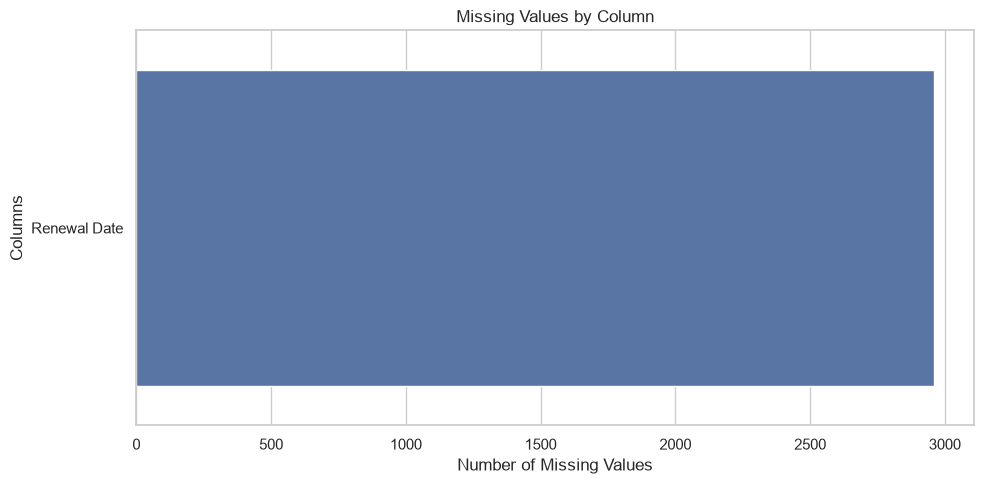

In [94]:
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(x=missing.values, y=missing.index)

plt.title("Missing Values by Column")
plt.xlabel("Number of Missing Values")
plt.ylabel("Columns")
plt.tight_layout()
plt.show()

## 2. Company Distribution by Country

This visualization shows the top 10 countries with the highest number of company records.


C:\Users\Neha\AppData\Local\Temp\ipykernel_23028\2581237797.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_countries.values, y=top_countries.index,edgecolor="k",palette="Set3")


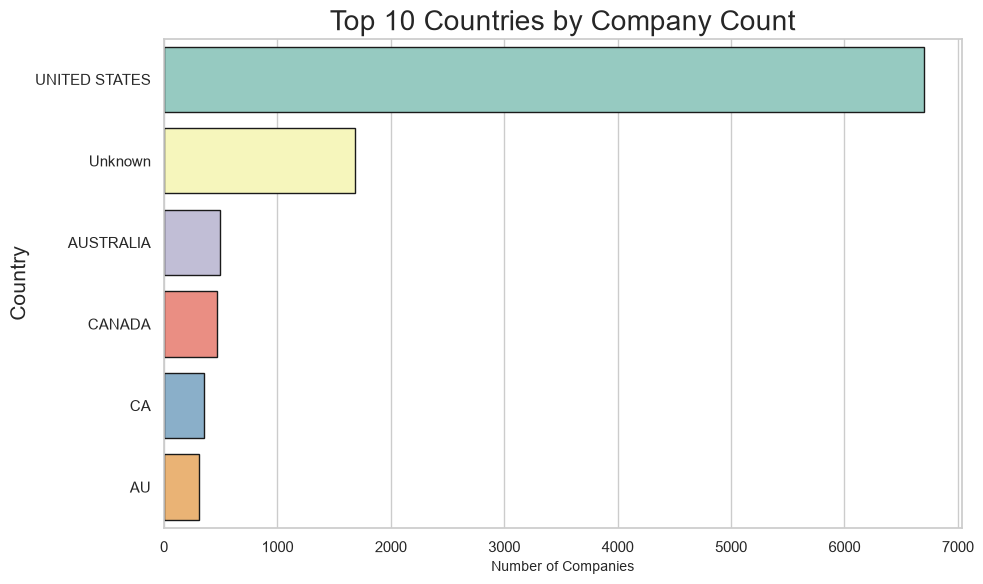

In [95]:
top_countries = df["Country"].value_counts().head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_countries.values, y=top_countries.index,edgecolor="k",palette="Set3")

plt.title("Top 10 Countries by Company Count",fontsize = 20)
plt.xlabel("Number of Companies",fontsize=10)
plt.ylabel("Country",fontsize= 15)
plt.tight_layout()
plt.show()

## 3. Lifecycle Stage Analysis

This chart examines how company records are distributed across lifecycle stages, helping us understand the composition of the company database.


C:\Users\Neha\AppData\Local\Temp\ipykernel_23028\1219732403.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


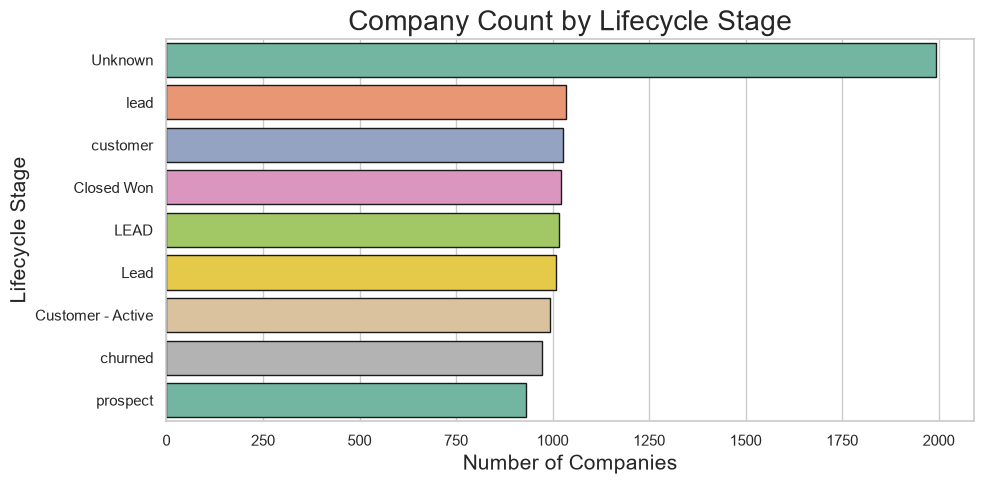

In [96]:
plt.figure(figsize=(10, 5))

order = df["Lifecycle Stage"].value_counts().index

sns.countplot(
    data=df,
    y="Lifecycle Stage",
    order=order,edgecolor = "k",palette="Set2"
)

plt.title("Company Count by Lifecycle Stage",fontsize=20)
plt.xlabel("Number of Companies",fontsize = 15)
plt.ylabel("Lifecycle Stage",fontsize = 15)
plt.tight_layout()
plt.show()

## 4. Employee Count Distribution

This visualization explores the distribution of company sizes using employee counts. It helps identify common company-size ranges and unusually large values.


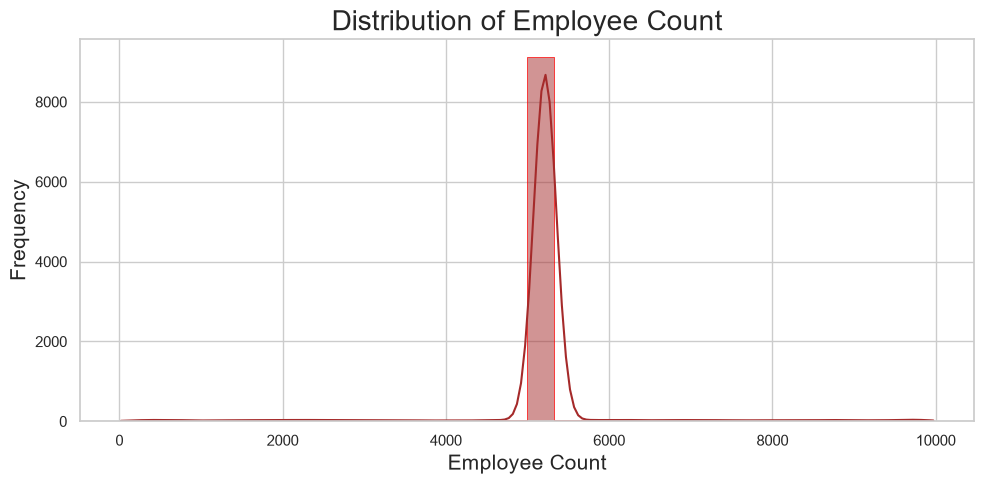

In [97]:
employees = pd.to_numeric(df["Employee Count"], errors="coerce")
employees = employees[employees.notna() & (employees >= 0)]

plt.figure(figsize=(10, 5))
sns.histplot(employees, bins=30, kde=True,linewidth=0.5,edgecolor = "red",color= "Brown")

plt.title("Distribution of Employee Count",fontsize = 20)
plt.xlabel("Employee Count",fontsize = 15)
plt.ylabel("Frequency",fontsize = 15)
plt.tight_layout()
plt.show()

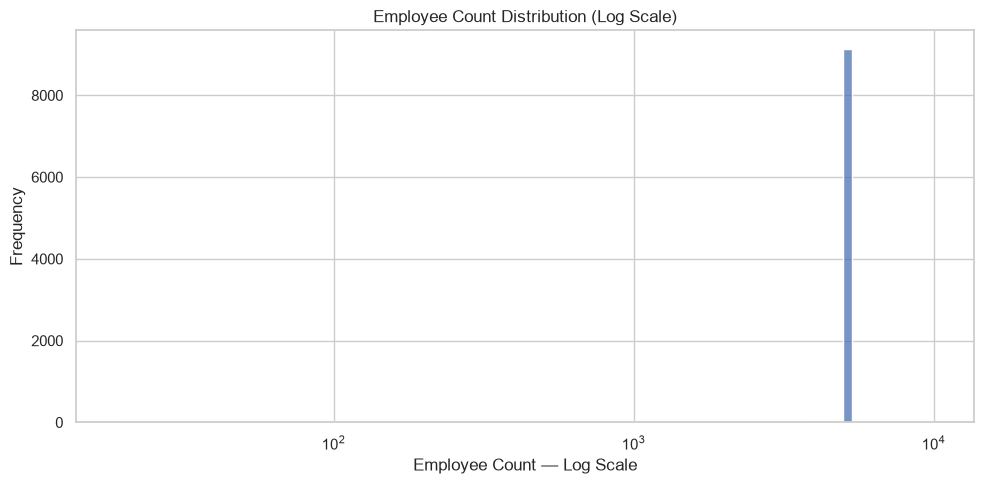

In [98]:
plt.figure(figsize=(10, 5))
sns.histplot(employees[employees > 0], bins=30)

plt.xscale("log")
plt.title("Employee Count Distribution (Log Scale)")
plt.xlabel("Employee Count — Log Scale")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

## 5. Lead Score Category Analysis

This chart displays the frequency of lead-score labels to understand which lead categories are most common in the dataset.


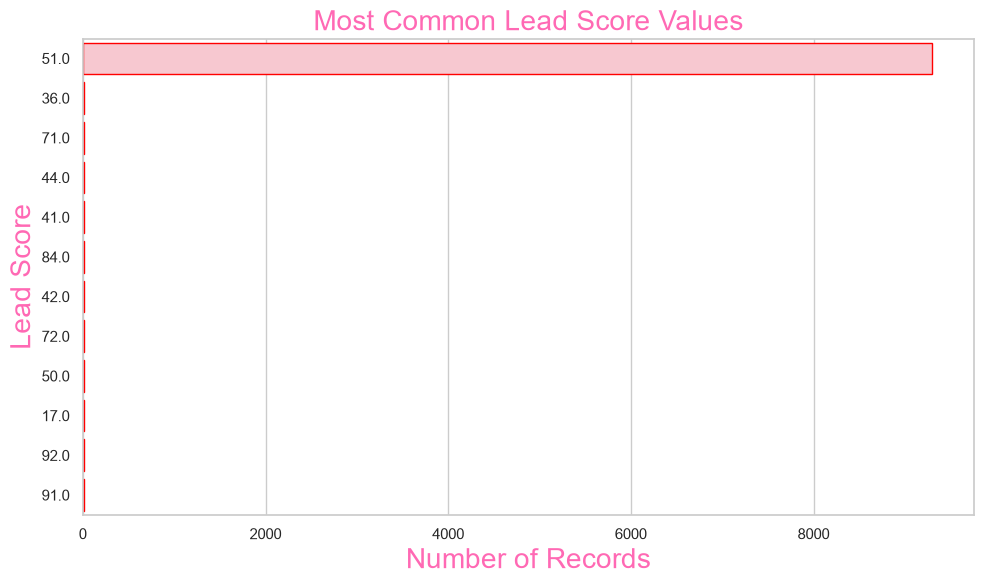

In [99]:
lead_counts = (
    df["Lead Score"]
    .fillna("Unknown")
    .astype(str)
    .value_counts()
    .head(12)
)

plt.figure(figsize=(10, 6))
sns.barplot(x=lead_counts.values, y=lead_counts.index,color="pink",edgecolor="red")

plt.title("Most Common Lead Score Values",fontsize= 20,color="hotpink")
plt.xlabel("Number of Records",fontsize= 20,color="hotpink")
plt.ylabel("Lead Score",fontsize= 20,color="hotpink")
plt.tight_layout()
plt.show()

## 6. Company Creation Trend

This time-series analysis tracks the number of company records created over time and helps identify periods with higher or lower record creation activity.


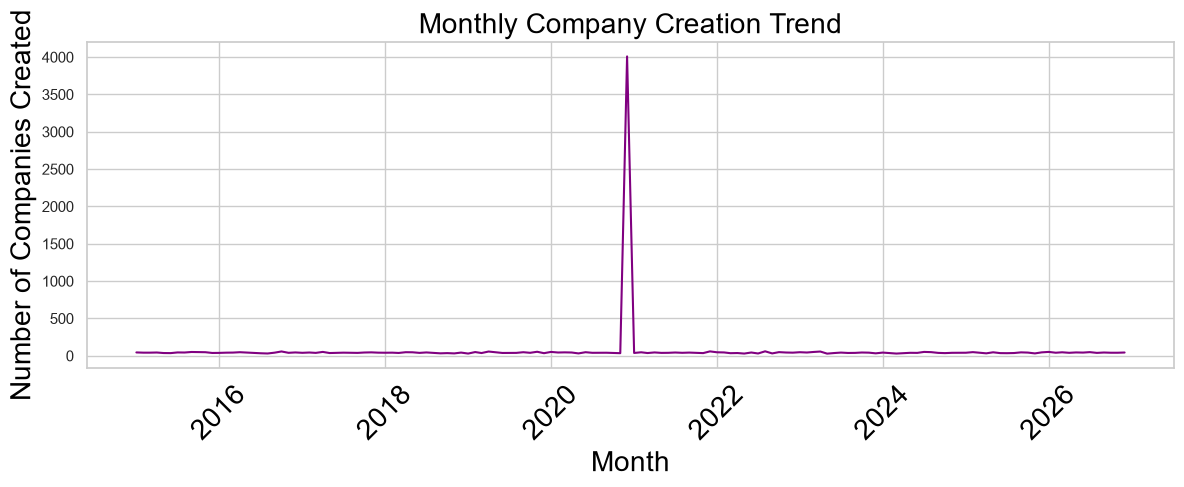

In [100]:
df["Created Date"] = pd.to_datetime(
    df["Created Date"], errors="coerce"
)

created_monthly = (
    df.dropna(subset=["Created Date"])
      .set_index("Created Date")
      .resample("MS")
      .size()
)

plt.figure(figsize=(12, 5))
sns.lineplot(x=created_monthly.index, y=created_monthly.values,color="purple")

plt.title("Monthly Company Creation Trend",fontsize= 20,color="black")
plt.xlabel("Month",fontsize= 20,color="black")
plt.ylabel("Number of Companies Created",fontsize= 20,color="black")
plt.xticks(rotation=45,fontsize= 20,color="black")
plt.tight_layout()
plt.show()

In [101]:
print(df[[
    "Employee Count",
    "Annual Revenue",
    "Lead Score",
    "Open Opportunities",
    "Renewal Date"
]].dtypes)

display(df[[
    "Employee Count",
    "Annual Revenue",
    "Lead Score",
    "Open Opportunities",
    "Renewal Date"
]].head(10))

Employee Count        float64
Annual Revenue        float64
Lead Score            float64
Open Opportunities    float64
Renewal Date              str
dtype: object


,Employee Count,Annual Revenue,Lead Score,Open Opportunities,Renewal Date
0,5213.5,5000000.0,51.0,0.0,2026-02-23
1,5213.5,5000000.0,51.0,0.0,2017-03-28
2,5213.5,5000000.0,51.0,0.0,2018-04-01
3,5213.5,5000000.0,51.0,0.0,2018-01-24
4,5213.5,5000000.0,51.0,1.0,2025-06-13
5,5213.5,5000000.0,51.0,0.0,2024-02-06
6,5213.5,5000000.0,51.0,0.0,NaN
7,5213.5,5000000.0,51.0,0.0,NaN
8,5213.5,5000000.0,51.0,0.0,NaN
9,5213.5,5000000.0,51.0,0.0,2018-01-08


## 7. Numerical Data Quality Check

Before performing advanced EDA, we inspect the distribution of numerical variables to identify repeated values, missing data, and potential data quality issues.


In [102]:
numeric_cols = [
    "Employee Count",
    "Annual Revenue",
    "Lead Score",
    "Open Opportunities"
]

print(df[numeric_cols].describe().round(2))

print("\nUnique values in each column:")
print(df[numeric_cols].nunique())

print("\nMissing values:")
print(df[numeric_cols].isnull().sum())

       Employee Count  Annual Revenue  Lead Score  Open Opportunities
count        10000.00         10000.0    10000.00            10000.00
mean          5200.53       5000000.0       51.06                0.86
std            878.04             0.0        7.58                2.43
min             19.00       5000000.0        0.00                0.00
25%           5213.50       5000000.0       51.00                0.00
50%           5213.50       5000000.0       51.00                0.00
75%           5213.50       5000000.0       51.00                0.00
max           9971.00       5000000.0      100.00               11.00

Unique values in each column:
Employee Count        855
Annual Revenue          1
Lead Score            101
Open Opportunities     12
dtype: int64

Missing values:
Employee Count        0
Annual Revenue        0
Lead Score            0
Open Opportunities    0
dtype: int64


## 11. Investigation of Repeated Values

This step investigates repeated numerical values to determine whether they represent genuine observations or values introduced during missing-data imputation.


In [103]:
cols = [
    "Employee Count",
    "Annual Revenue",
    "Lead Score",
    "Open Opportunities"
]

for col in cols:
    print(f"\n--- {col} ---")
    print(df[col].value_counts().head(10))


--- Employee Count ---
Employee Count
5213.5    9110
2683.0       3
4685.0       2
9597.0       2
7182.0       2
440.0        2
8238.0       2
9830.0       2
714.0        2
1237.0       2
Name: count, dtype: int64

--- Annual Revenue ---
Annual Revenue
5000000.0    10000
Name: count, dtype: int64

--- Lead Score ---
Lead Score
51.0    9292
36.0      14
71.0      14
44.0      14
41.0      11
84.0      11
42.0      11
72.0      11
50.0      11
17.0      10
Name: count, dtype: int64

--- Open Opportunities ---
Open Opportunities
0.0     8600
8.0      143
9.0      141
4.0      135
7.0      130
11.0     129
6.0      126
2.0      126
10.0     124
5.0      118
Name: count, dtype: int64


In [104]:
df_original = pd.read_csv(r"D:\Debugshala\Python\pandas\cleaned_company_data.csv"
)

In [105]:
for col in cols:
    print(f"\n{col}")
    print("Original unique:", df_original[col].nunique())
    print("Cleaned unique:", df[col].nunique())


Employee Count
Original unique: 855
Cleaned unique: 855

Annual Revenue
Original unique: 1
Cleaned unique: 1

Lead Score
Original unique: 101
Cleaned unique: 101

Open Opportunities
Original unique: 12
Cleaned unique: 12


In [106]:
print(df["Annual Revenue"].value_counts(dropna=False))

Annual Revenue
5000000.0    10000
Name: count, dtype: int64


## 12. Relationship Between Company Size and Lead Score

This scatter plot explores whether employee count is associated with lead scores. It helps identify patterns between company size and lead qualification scores.


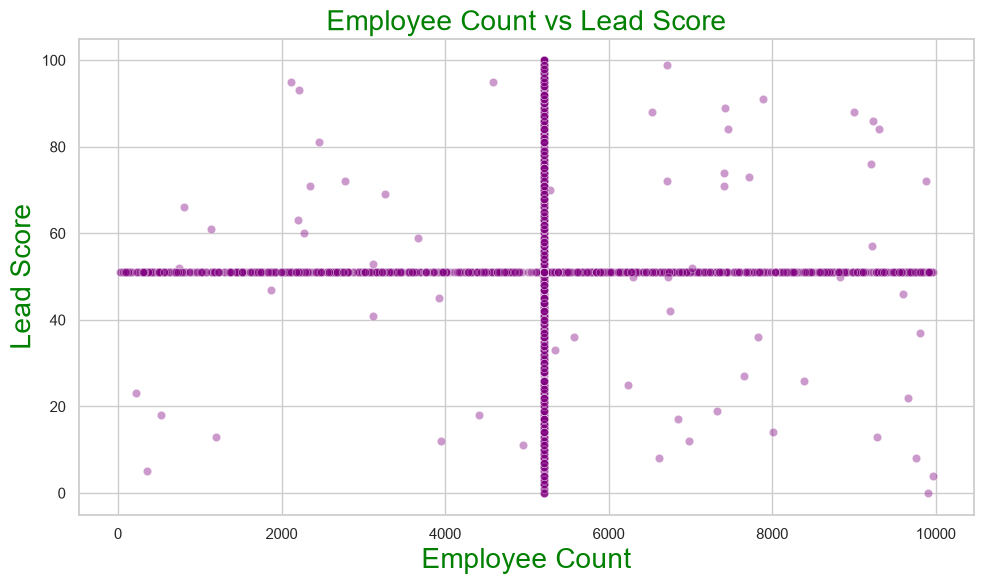

In [107]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Employee Count",
    y="Lead Score",
    alpha=0.4,color="purple"
)

plt.title("Employee Count vs Lead Score",fontsize= 20,color="green")
plt.xlabel("Employee Count",fontsize= 20,color="green")
plt.ylabel("Lead Score",fontsize= 20,color="green")
plt.tight_layout()
plt.show()

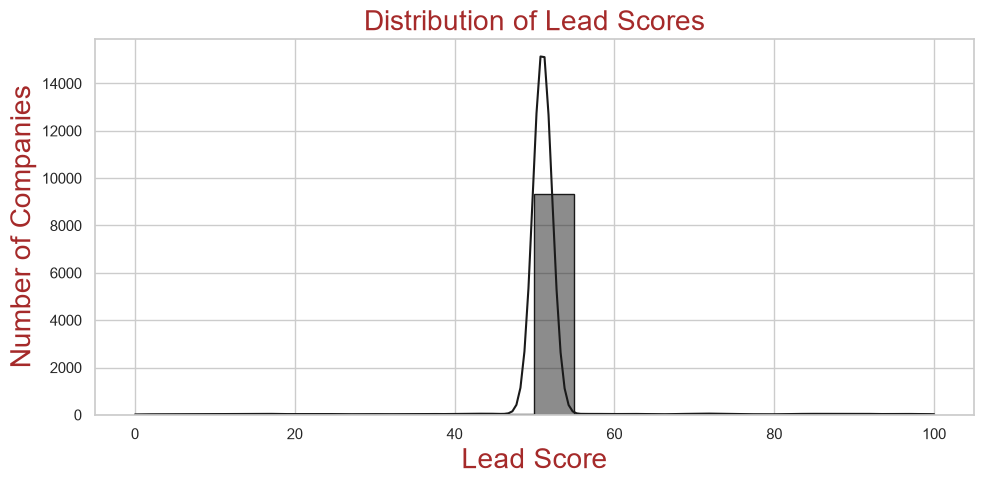

In [108]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Lead Score",
    bins=20,
    kde=True,color="k",edgecolor="k"
)

plt.title("Distribution of Lead Scores",fontsize= 20,color="brown")
plt.xlabel("Lead Score",fontsize= 20,color="brown")
plt.ylabel("Number of Companies",fontsize= 20,color="brown")
plt.tight_layout()
plt.show()

## 13. Open Opportunities by Lifecycle Stage

This analysis compares the average number of open opportunities across lifecycle stages to identify which stages have greater sales opportunity activity.


C:\Users\Neha\AppData\Local\Temp\ipykernel_23028\2734206409.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


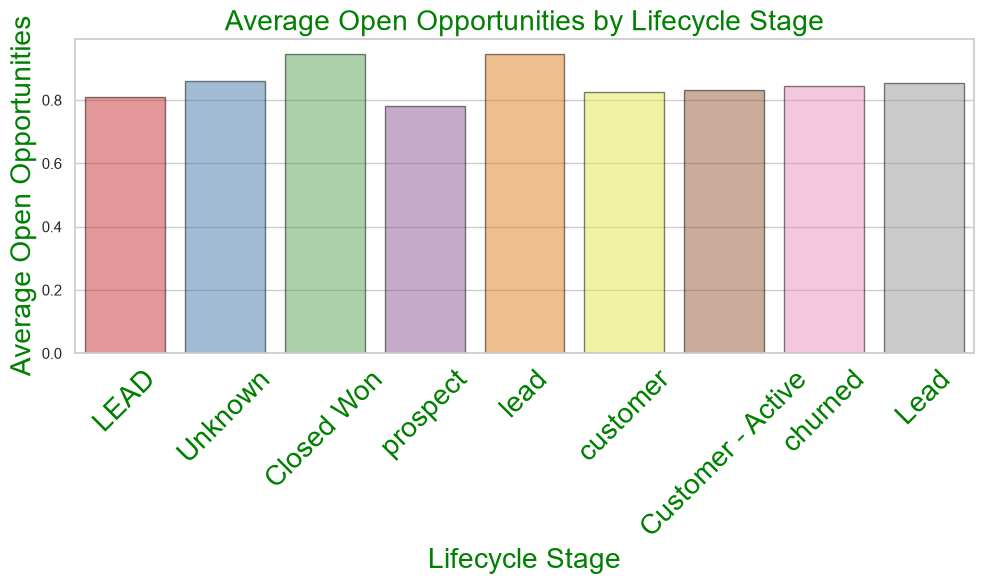

In [109]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=df,
    x="Lifecycle Stage",
    y="Open Opportunities",
    estimator="mean",
    errorbar=None,palette="Set1",edgecolor="black",alpha=0.5
)

plt.title("Average Open Opportunities by Lifecycle Stage",fontsize= 20,color="green")
plt.xlabel("Lifecycle Stage",fontsize= 20,color="green")
plt.ylabel("Average Open Opportunities",fontsize= 20,color="green")
plt.xticks(rotation=45,fontsize= 20,color="green")
plt.tight_layout()
plt.show()

## 14. Company Size Across Lifecycle Stages

This box plot compares employee counts across lifecycle stages and helps identify differences in company size and potential outliers.


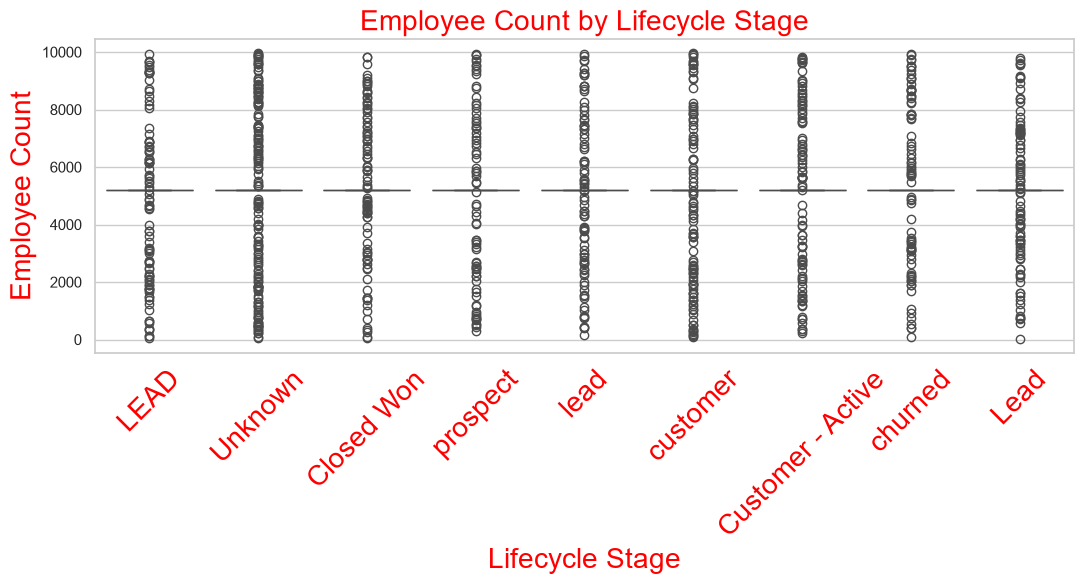

In [110]:
plt.figure(figsize=(11, 6))

sns.boxplot(
    data=df,
    x="Lifecycle Stage",
    y="Employee Count"
)

plt.title("Employee Count by Lifecycle Stage",fontsize= 20,color="red")
plt.xlabel("Lifecycle Stage",fontsize= 20,color="red")
plt.ylabel("Employee Count",fontsize= 20,color="red")
plt.xticks(rotation=45,fontsize= 20,color="red")
plt.tight_layout()
plt.show()

## 15. Lead Score Across Lifecycle Stages

This visualization compares lead-score distributions across lifecycle stages to explore whether lead qualification scores differ between groups.


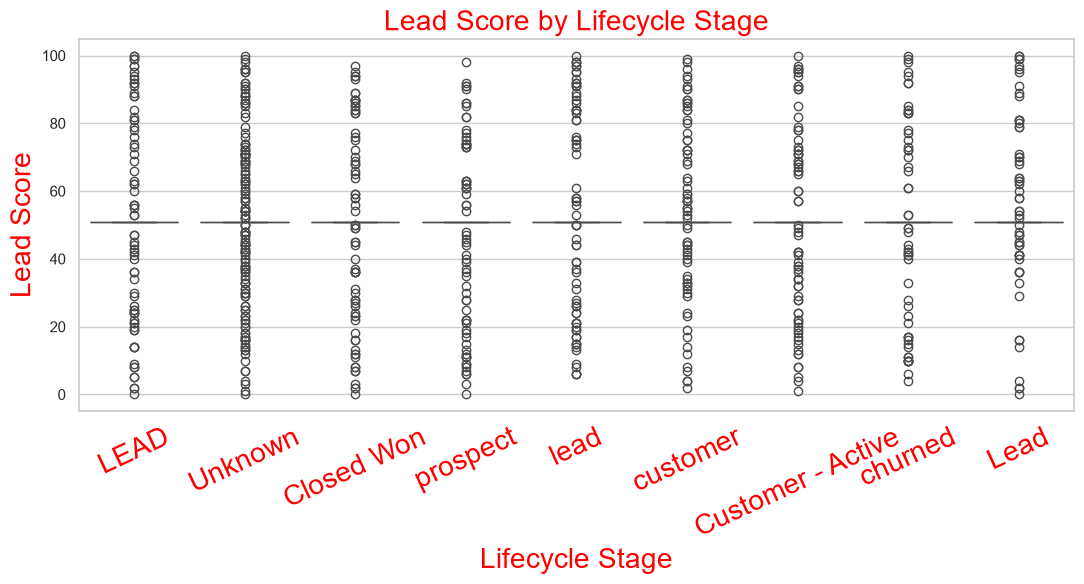

In [111]:
plt.figure(figsize=(11, 6))

sns.boxplot(
    data=df,
    x="Lifecycle Stage",
    y="Lead Score",
)

plt.title("Lead Score by Lifecycle Stage",fontsize= 20,color="red")
plt.xlabel("Lifecycle Stage",fontsize= 20,color= "red")
plt.ylabel("Lead Score",fontsize= 20,color = "red")
plt.xticks(rotation=25,fontsize= 20,color = "red")
plt.tight_layout()
plt.show()

# 16. Key Findings and Business Insights

The visual analysis of the company dataset helps us explore company distribution, lifecycle stages, employee counts, lead scores, and sales opportunities.

The following insights should be documented after reviewing the charts:

* **Geographic Distribution:** Identify the countries with the highest number of company records.
* **Lifecycle Analysis:** Determine which lifecycle stages contain the most company records.
* **Company Size:** Examine the distribution of employee counts and identify unusually large or small values.
* **Lead Score Analysis:** Explore the distribution of lead scores and differences across lifecycle stages.
* **Sales Opportunities:** Compare open opportunities across lifecycle stages.
* **Data Quality:** Annual Revenue contains only one unique value in the original dataset, limiting revenue-related analysis.
* **Date Analysis:** Examine company creation trends while considering missing or imputed dates.

Business conclusions should be based on the actual chart results rather than assumptions.


In [112]:
# Step 17 — Final data quality check
print("Dataset shape:", df.shape)

print("\nDuplicate rows:", df.duplicated().sum())

print("\nMissing values:")
print(df.isnull().sum())

print("\nData types:")
print(df.dtypes)

Dataset shape: (10000, 17)

Duplicate rows: 0

Missing values:
Index                     0
Row ID                    0
Raw Company Name          0
Website                   0
Company Description       0
Country                   0
Source System             0
Account Owner             0
Created Date              0
Last Activity Date        0
Renewal Date           2960
Lifecycle Stage           0
Employee Count            0
Annual Revenue            0
Lead Score                0
Open Opportunities        0
CRM Notes                 0
dtype: int64

Data types:
Index                           int64
Row ID                            str
Raw Company Name                  str
Website                           str
Company Description               str
Country                           str
Source System                     str
Account Owner                     str
Created Date           datetime64[us]
Last Activity Date                str
Renewal Date                      str
Lifecycle Stage  

In [113]:
# Step 18 — Save the final dataset
df.to_csv(
    r"C:\Users\Neha\Downloads\cleaned_company_data_final.csv",
    index=False
)

### Visualization Style

A consistent chart style is used throughout the analysis to make the
visualizations easier to read.

In [114]:
sns.set_theme(style="whitegrid", context="notebook")

plt.rcParams.update({
    "figure.figsize": (9, 5),
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.dpi": 120
})

## 17. Company Distribution by Lifecycle Stage

A pie chart is used to visualize the proportion of company records across different lifecycle stages. It helps identify which stages account for the largest share of the dataset.


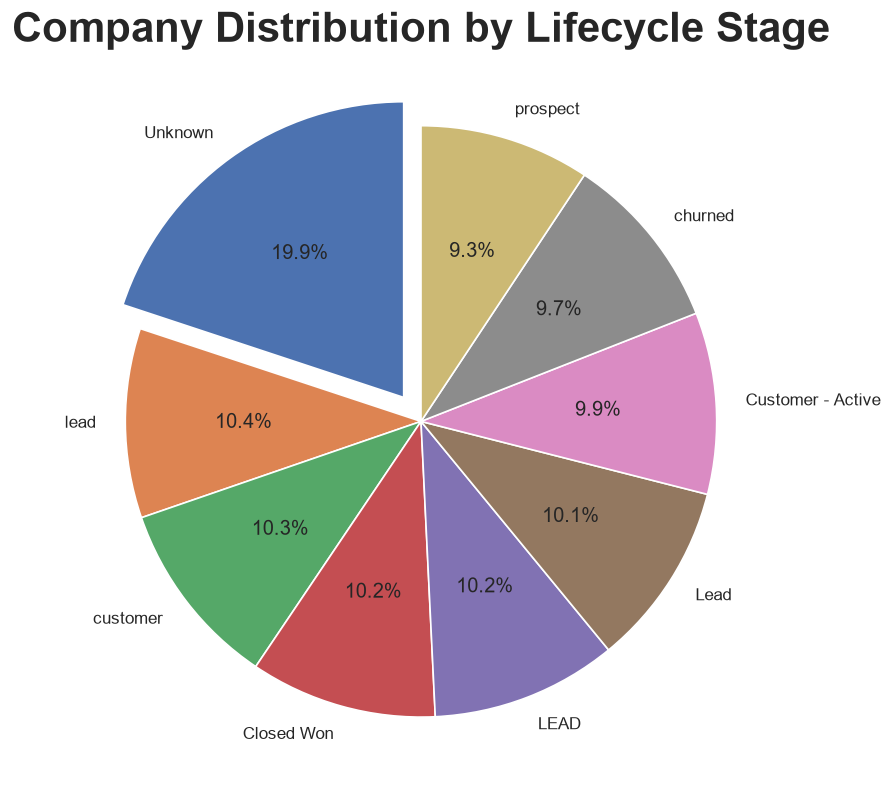

In [115]:
lifecycle_counts = df["Lifecycle Stage"].fillna("Unknown").value_counts()

# First slice ko explode karo, baaki normal rahengi
explode = [0.1] + [0] * (len(lifecycle_counts) - 1)

plt.figure(figsize=(8, 8))

plt.pie(
    lifecycle_counts.values,
    labels=lifecycle_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    explode=explode
)

plt.title("Company Distribution by Lifecycle Stage",fontsize=25)
plt.show()

## 18. Renewal Date Availability

This pie chart compares records with known renewal dates against records with unknown renewal dates. It highlights the completeness of renewal-date information.


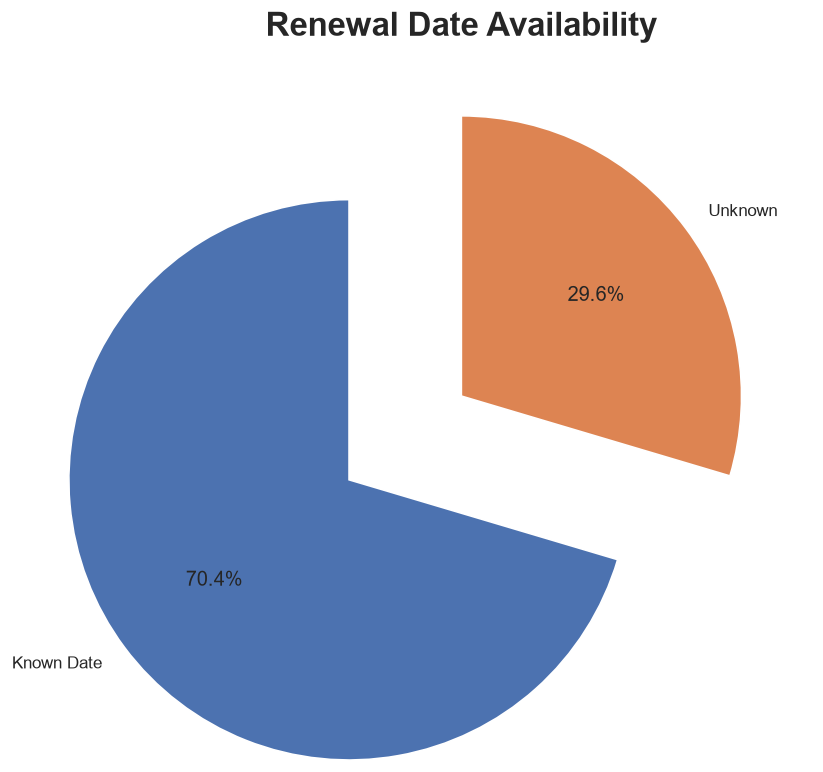

In [116]:
renewal = df["Renewal Date"].fillna("Unknown").astype(str).str.strip()

renewal_status = renewal.apply(
    lambda x: "Unknown"
    if x.lower() in ["unknown", "nan", "nat", ""]
    else "Known Date"
).value_counts()

plt.figure(figsize=(7, 7))

plt.pie(
    renewal_status.values,
    labels=renewal_status.index,
    autopct="%1.1f%%",
    startangle=90,explode=[0.5,0.0]
)

plt.title("Renewal Date Availability",fontsize = 20)
plt.tight_layout()
plt.show()

## 19. Correlation Heatmap of Company Metrics

A correlation heatmap visualizes relationships between numerical variables. Values closer to +1 indicate positive linear relationships, values closer to -1 indicate negative linear relationships, and values near 0 indicate weak linear relationships.


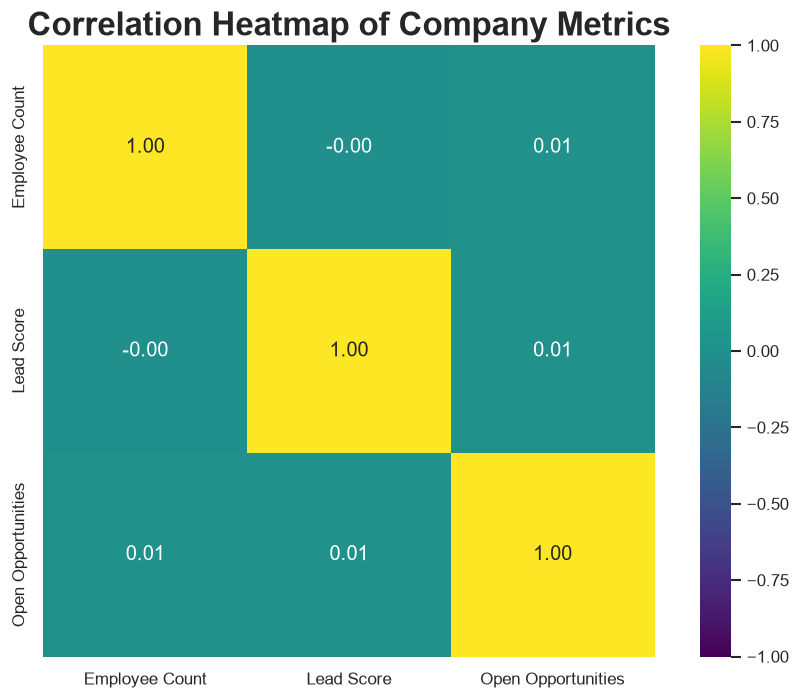

In [117]:
import seaborn as sns
import matplotlib.pyplot as plt

heatmap_cols = [
    "Employee Count",
    "Lead Score",
    "Open Opportunities"
]

corr = df[heatmap_cols].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    corr,
    annot=True,
    cmap="viridis",
    vmin=-1,
    vmax=1,
    fmt=".2f",
    square=True,
)

plt.title("Correlation Heatmap of Company Metrics",fontsize=20)
plt.tight_layout()
plt.show()

## 20. Lifecycle Stage vs Open Opportunities

This heatmap shows the number of company records for each combination of lifecycle stage and open opportunities. It helps reveal where opportunity counts are concentrated across lifecycle stages.


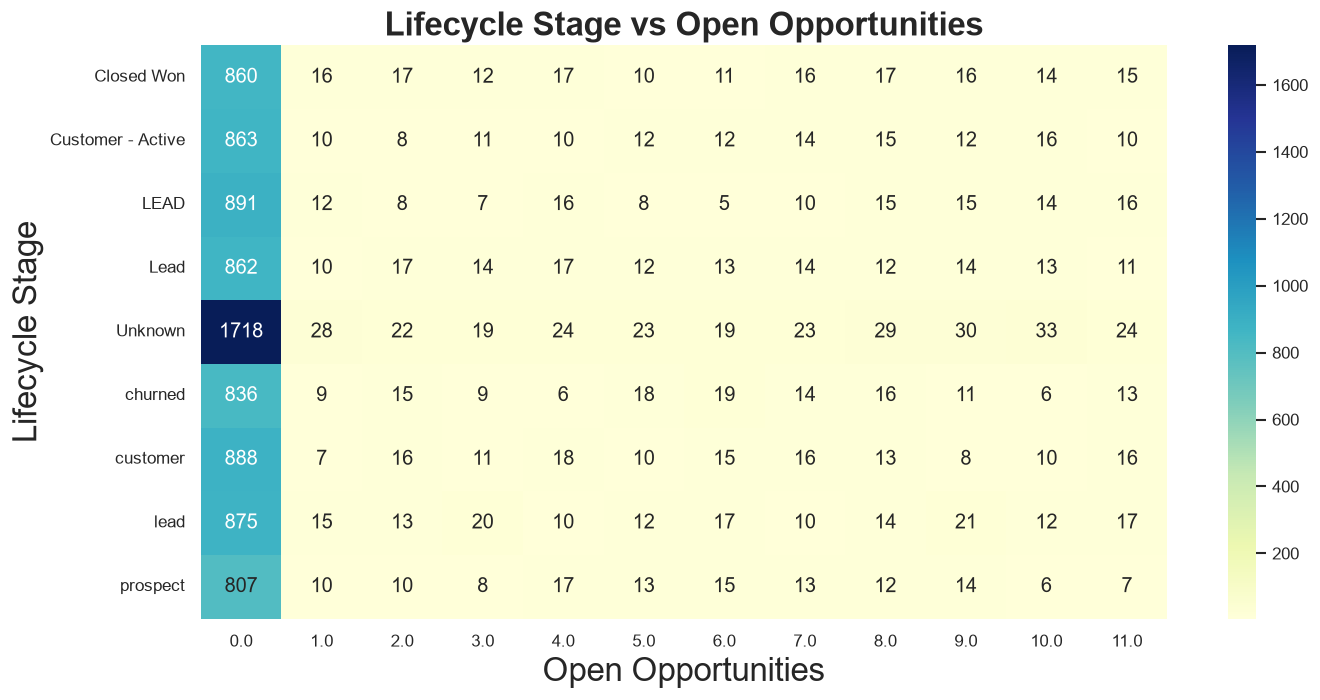

In [118]:
pivot_data = pd.crosstab(
    df["Lifecycle Stage"].fillna("Unknown"),
    df["Open Opportunities"]
)

plt.figure(figsize=(12, 6))

sns.heatmap(
    pivot_data,
    annot=True,
    fmt="d",
    cmap="YlGnBu"
)

plt.title("Lifecycle Stage vs Open Opportunities",fontsize = 20)
plt.xlabel("Open Opportunities",fontsize = 20)
plt.ylabel("Lifecycle Stage",fontsize = 20)
plt.tight_layout()
plt.show()

# 16. Key Findings and Business Insights

The visual analysis of the company dataset helps us explore company distribution, lifecycle stages, employee counts, lead scores, and sales opportunities.

The following insights should be documented after reviewing the charts:

* **Geographic Distribution:** Identify the countries with the highest number of company records.
* **Lifecycle Analysis:** Determine which lifecycle stages contain the most company records.
* **Company Size:** Examine the distribution of employee counts and identify unusually large or small values.
* **Lead Score Analysis:** Explore the distribution of lead scores and differences across lifecycle stages.
* **Sales Opportunities:** Compare open opportunities across lifecycle stages.
* **Data Quality:** Annual Revenue contains only one unique value in the original dataset, limiting revenue-related analysis.
* **Date Analysis:** Examine company creation trends while considering missing or imputed dates.

Business conclusions should be based on the actual chart results rather than assumptions.


In [119]:

# ==========================================
# KEY FINDINGS & BUSINESS INSIGHTS
# Company Data Cleaning and EDA Project
# ==========================================

# 1. Dataset Overview
print("=" * 55)
print("1. DATASET OVERVIEW")
print("=" * 55)

print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])
print("Duplicate Rows:", df.duplicated().sum())

# 2. Missing Values
print("\n" + "=" * 55)
print("2. MISSING VALUES")
print("=" * 55)

missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

if missing.empty:
    print("No missing values found.")
else:
    print(missing)

# 3. Top Countries
print("\n" + "=" * 55)
print("3. TOP 10 COUNTRIES")
print("=" * 55)

print(
    df["Country"]
    .fillna("Unknown")
    .value_counts()
    .head(10)
)

# 4. Lifecycle Stage Distribution
print("\n" + "=" * 55)
print("4. LIFECYCLE STAGE DISTRIBUTION")
print("=" * 55)

lifecycle_counts = (
    df["Lifecycle Stage"]
    .fillna("Unknown")
    .value_counts()
)

print(lifecycle_counts)

# 5. Numeric Summary
print("\n" + "=" * 55)
print("5. NUMERIC SUMMARY")
print("=" * 55)

numeric_cols = [
    "Employee Count",
    "Annual Revenue",
    "Lead Score",
    "Open Opportunities"
]

print(df[numeric_cols].describe().round(2))

# 6. Revenue Data Quality Check
print("\n" + "=" * 55)
print("6. ANNUAL REVENUE CHECK")
print("=" * 55)

print("Unique revenue values:", df["Annual Revenue"].nunique())
print("Revenue values:")
print(df["Annual Revenue"].value_counts().head())

# 7. Lead Score Insights
print("\n" + "=" * 55)
print("7. LEAD SCORE INSIGHTS")
print("=" * 55)

print("Average Lead Score:", round(df["Lead Score"].mean(), 2))
print("Highest Lead Score:", df["Lead Score"].max())
print("Lowest Lead Score:", df["Lead Score"].min())

# 8. Open Opportunities Insights
print("\n" + "=" * 55)
print("8. OPEN OPPORTUNITIES")
print("=" * 55)

print("Average Open Opportunities:",
      round(df["Open Opportunities"].mean(), 2))

print("Maximum Open Opportunities:",
      df["Open Opportunities"].max())

print("\nAverage Opportunities by Lifecycle Stage:")

print(
    df.groupby("Lifecycle Stage", dropna=False)
      ["Open Opportunities"]
      .mean()
      .round(2)
      .sort_values(ascending=False)
)

# 9. Employee Count Quality Check
print("\n" + "=" * 55)
print("9. EMPLOYEE COUNT DISTRIBUTION")
print("=" * 55)

print(df["Employee Count"].describe().round(2))

print(
    "Unique Employee Count values:",
    df["Employee Count"].nunique()
)

print(
    "Number of records equal to median:",
    (df["Employee Count"] == df["Employee Count"].median()).sum()
)

# 10. Renewal Date Availability
print("\n" + "=" * 55)
print("10. RENEWAL DATE STATUS")
print("=" * 55)

renewal = df["Renewal Date"].fillna("Unknown").astype(str).str.strip()

renewal_status = renewal.apply(
    lambda x: "Unknown"
    if x.lower() in ["unknown", "nan", "nat", ""]
    else "Available"
)

print(renewal_status.value_counts())

# 11. Correlation Analysis
print("\n" + "=" * 55)
print("11. CORRELATION ANALYSIS")
print("=" * 55)

correlation_cols = [
    "Employee Count",
    "Lead Score",
    "Open Opportunities"
]

print(
    df[correlation_cols]
    .corr()
    .round(2)
)

print("\nKEY FINDINGS ANALYSIS COMPLETED!")


1. DATASET OVERVIEW
Total Rows: 10000
Total Columns: 17
Duplicate Rows: 0

2. MISSING VALUES
Renewal Date    2960
dtype: int64

3. TOP 10 COUNTRIES
Country
UNITED STATES    6697
Unknown          1687
AUSTRALIA         492
CANADA            470
CA                349
AU                305
Name: count, dtype: int64

4. LIFECYCLE STAGE DISTRIBUTION
Lifecycle Stage
Unknown              1992
lead                 1036
customer             1028
Closed Won           1021
LEAD                 1017
Lead                 1009
Customer - Active     993
churned               972
prospect              932
Name: count, dtype: int64

5. NUMERIC SUMMARY
       Employee Count  Annual Revenue  Lead Score  Open Opportunities
count        10000.00         10000.0    10000.00            10000.00
mean          5200.53       5000000.0       51.06                0.86
std            878.04             0.0        7.58                2.43
min             19.00       5000000.0        0.00                0.00
25%    

# Key Findings & Business Insights

## 1. Dataset Overview
The dataset contains company-level information, including country, employee count, annual revenue, lead score, lifecycle stage, renewal dates, and open opportunities. Data cleaning and exploratory data analysis (EDA) were performed to improve data quality and understand business patterns.

## 2. Data Quality and Cleaning
- Checked missing values, duplicate records, inconsistent formats, and data types.
- Standardized country names and cleaned numeric fields.
- Processed date columns and handled missing renewal dates using an appropriate unknown-value category.
- Investigated unusual and inconsistent values to improve data reliability.

## 3. Lead Score Analysis
The average lead score is approximately **51.06**, with scores ranging from **0 to 100**. This provides an overview of lead scoring across the dataset. Further segmentation can help identify high-scoring leads for sales follow-up.

## 4. Open Opportunities
The average number of open opportunities is approximately **0.86 per company**, with a maximum of **11**. Comparing opportunities across lifecycle stages can help identify where sales activity is concentrated.

## 5. Employee Count Analysis
The employee count distribution requires careful interpretation. The first quartile, median, and third quartile were all approximately **5,213.5** in the cleaned data. This unusual pattern may indicate that many missing or inconsistent values were replaced with the median. It should be investigated before using employee count for business decisions.

## 6. Annual Revenue Data Limitation
Annual revenue has only **one unique value** in the cleaned dataset: ₹/$ value as recorded in the source data, currently **5,000,000** for every row. Therefore, meaningful revenue comparisons, revenue trends, and correlations involving annual revenue cannot be derived from this dataset in its current form.

## 7. Country and Lifecycle Stage Analysis
Country-wise and lifecycle-stage distributions help describe the composition of the dataset. The most frequent countries and lifecycle stages should be identified from the frequency tables and visualizations generated during EDA.

## 8. Business Recommendations
- Prioritize high-scoring leads for further sales review.
- Compare open opportunities across lifecycle stages to identify areas needing attention.
- Verify the employee count values and the method used to fill missing data.
- Obtain more varied and reliable revenue data before conducting revenue-based analysis.
- Maintain consistent data-entry standards and regularly monitor missing values.

## Conclusion
This project demonstrates data cleaning, data quality validation, statistical analysis, and exploratory visualization using Python, Pandas, NumPy, Matplotlib, and Seaborn. The analysis also highlights limitations in the source data that should be addressed before drawing stronger business conclusions.